In [3]:
"""
Fluoride Prediction - 5 Model Comparison
Models: XGBoost, Random Forest, SVR, Ridge Regression, Gradient Boosting
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
import xgboost as xgb

print("✅ Imports done")

✅ Imports done


In [4]:
# ─────────────────────────────────────────────
# 1. Load & Prepare Data
# ─────────────────────────────────────────────
df = pd.read_csv("data.csv")
print(f"Dataset shape: {df.shape}")

cols_to_drop = [c for c in ["SlNo", "Unnamed: 5"] if c in df.columns]
df = df.drop(columns=cols_to_drop)

features = [
    'Initial Fluoride Concentration (mg/L)',
    'pH',
    'Adsorbent Dose (g/100 mL)',
    'Contact Time (min)'
]
target = 'Result'

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")

Dataset shape: (23100, 7)
Train: 18480 samples | Test: 4620 samples


In [5]:
# ─────────────────────────────────────────────
# 2. Model Definitions with Hyperparameter Grids
# ─────────────────────────────────────────────

models_config = {

    "XGBoost": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", xgb.XGBRegressor(objective="reg:squarederror", random_state=42))
        ]),
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5],
            "model__learning_rate": [0.05, 0.1],
            "model__subsample": [0.8, 1.0],
            "model__colsample_bytree": [0.8, 1.0]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", RandomForestRegressor(random_state=42))
        ]),
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10],
            "model__min_samples_split": [2, 5],
            "model__min_samples_leaf": [1, 2]
        }
    },

    "SVR": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVR())
        ]),
        "params": {
            "model__C": [1, 10, 100],
            "model__epsilon": [0.01, 0.1],
            "model__kernel": ["rbf"],
            "model__gamma": ["scale"]
        }
    },

    "Ridge Regression": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge())
        ]),
        "params": {
            "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
        }
    },

    "Gradient Boosting": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("model", GradientBoostingRegressor(random_state=42))
        ]),
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5],
            "model__learning_rate": [0.05, 0.1],
            "model__subsample": [0.8, 1.0]
        }
    }
}

print("✅ Model configs ready")

✅ Model configs ready


In [6]:
# ─────────────────────────────────────────────
# 3. Train All Models with GridSearchCV
# ─────────────────────────────────────────────

results = {}

for name, config in models_config.items():
    print(f"▶  Training {name} ...")
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=5,
        scoring="r2",
        n_jobs=1
    )
    grid.fit(X_train, y_train)
    best = grid.best_estimator_

    y_pred_train = best.predict(X_train)
    y_pred_test  = best.predict(X_test)

    results[name] = {
        "best_params":    grid.best_params_,
        "model":          best,
        "y_pred_train":   y_pred_train,
        "y_pred_test":    y_pred_test,
        "train_r2":       r2_score(y_train, y_pred_train),
        "test_r2":        r2_score(y_test,  y_pred_test),
        "train_rmse":     np.sqrt(mean_squared_error(y_train, y_pred_train)),
        "test_rmse":      np.sqrt(mean_squared_error(y_test,  y_pred_test)),
        "train_mae":      mean_absolute_error(y_train, y_pred_train),
        "test_mae":       mean_absolute_error(y_test,  y_pred_test),
        "test_max_error": np.max(np.abs(y_test.values - y_pred_test)),
    }

    print(f"   Best CV R² : {grid.best_score_:.4f}")
    print(f"   Test  R²  : {results[name]['test_r2']:.4f}")
    print(f"   Test  RMSE: {results[name]['test_rmse']:.4f}")
    print(f"   Test  MAE : {results[name]['test_mae']:.4f}")
    print()

print("✅ All models trained")

▶  Training XGBoost ...
   Best CV R² : 0.9997
   Test  R²  : 0.9997
   Test  RMSE: 0.3441
   Test  MAE : 0.2613

▶  Training Random Forest ...
   Best CV R² : 0.9994
   Test  R²  : 0.9996
   Test  RMSE: 0.3990
   Test  MAE : 0.2718

▶  Training SVR ...
   Best CV R² : 1.0000
   Test  R²  : 1.0000
   Test  RMSE: 0.0140
   Test  MAE : 0.0077

▶  Training Ridge Regression ...
   Best CV R² : 0.8255
   Test  R²  : 0.8148
   Test  RMSE: 8.7795
   Test  MAE : 6.7863

▶  Training Gradient Boosting ...
   Best CV R² : 0.9995
   Test  R²  : 0.9995
   Test  RMSE: 0.4560
   Test  MAE : 0.3429

✅ All models trained


In [7]:
# ─────────────────────────────────────────────
# 4. Print Summary Table
# ─────────────────────────────────────────────

print("\n" + "=" * 65)
print(f"{'Model':<22} {'Train R²':>9} {'Test R²':>9} {'RMSE':>9} {'MAE':>9}")
print("=" * 65)
for name, r in results.items():
    print(f"{name:<22} {r['train_r2']:>9.4f} {r['test_r2']:>9.4f} "
          f"{r['test_rmse']:>9.4f} {r['test_mae']:>9.4f}")
print("=" * 65)


Model                   Train R²   Test R²      RMSE       MAE
XGBoost                   0.9998    0.9997    0.3441    0.2613
Random Forest             0.9999    0.9996    0.3990    0.2718
SVR                       1.0000    1.0000    0.0140    0.0077
Ridge Regression          0.8258    0.8148    8.7795    6.7863
Gradient Boosting         0.9996    0.9995    0.4560    0.3429


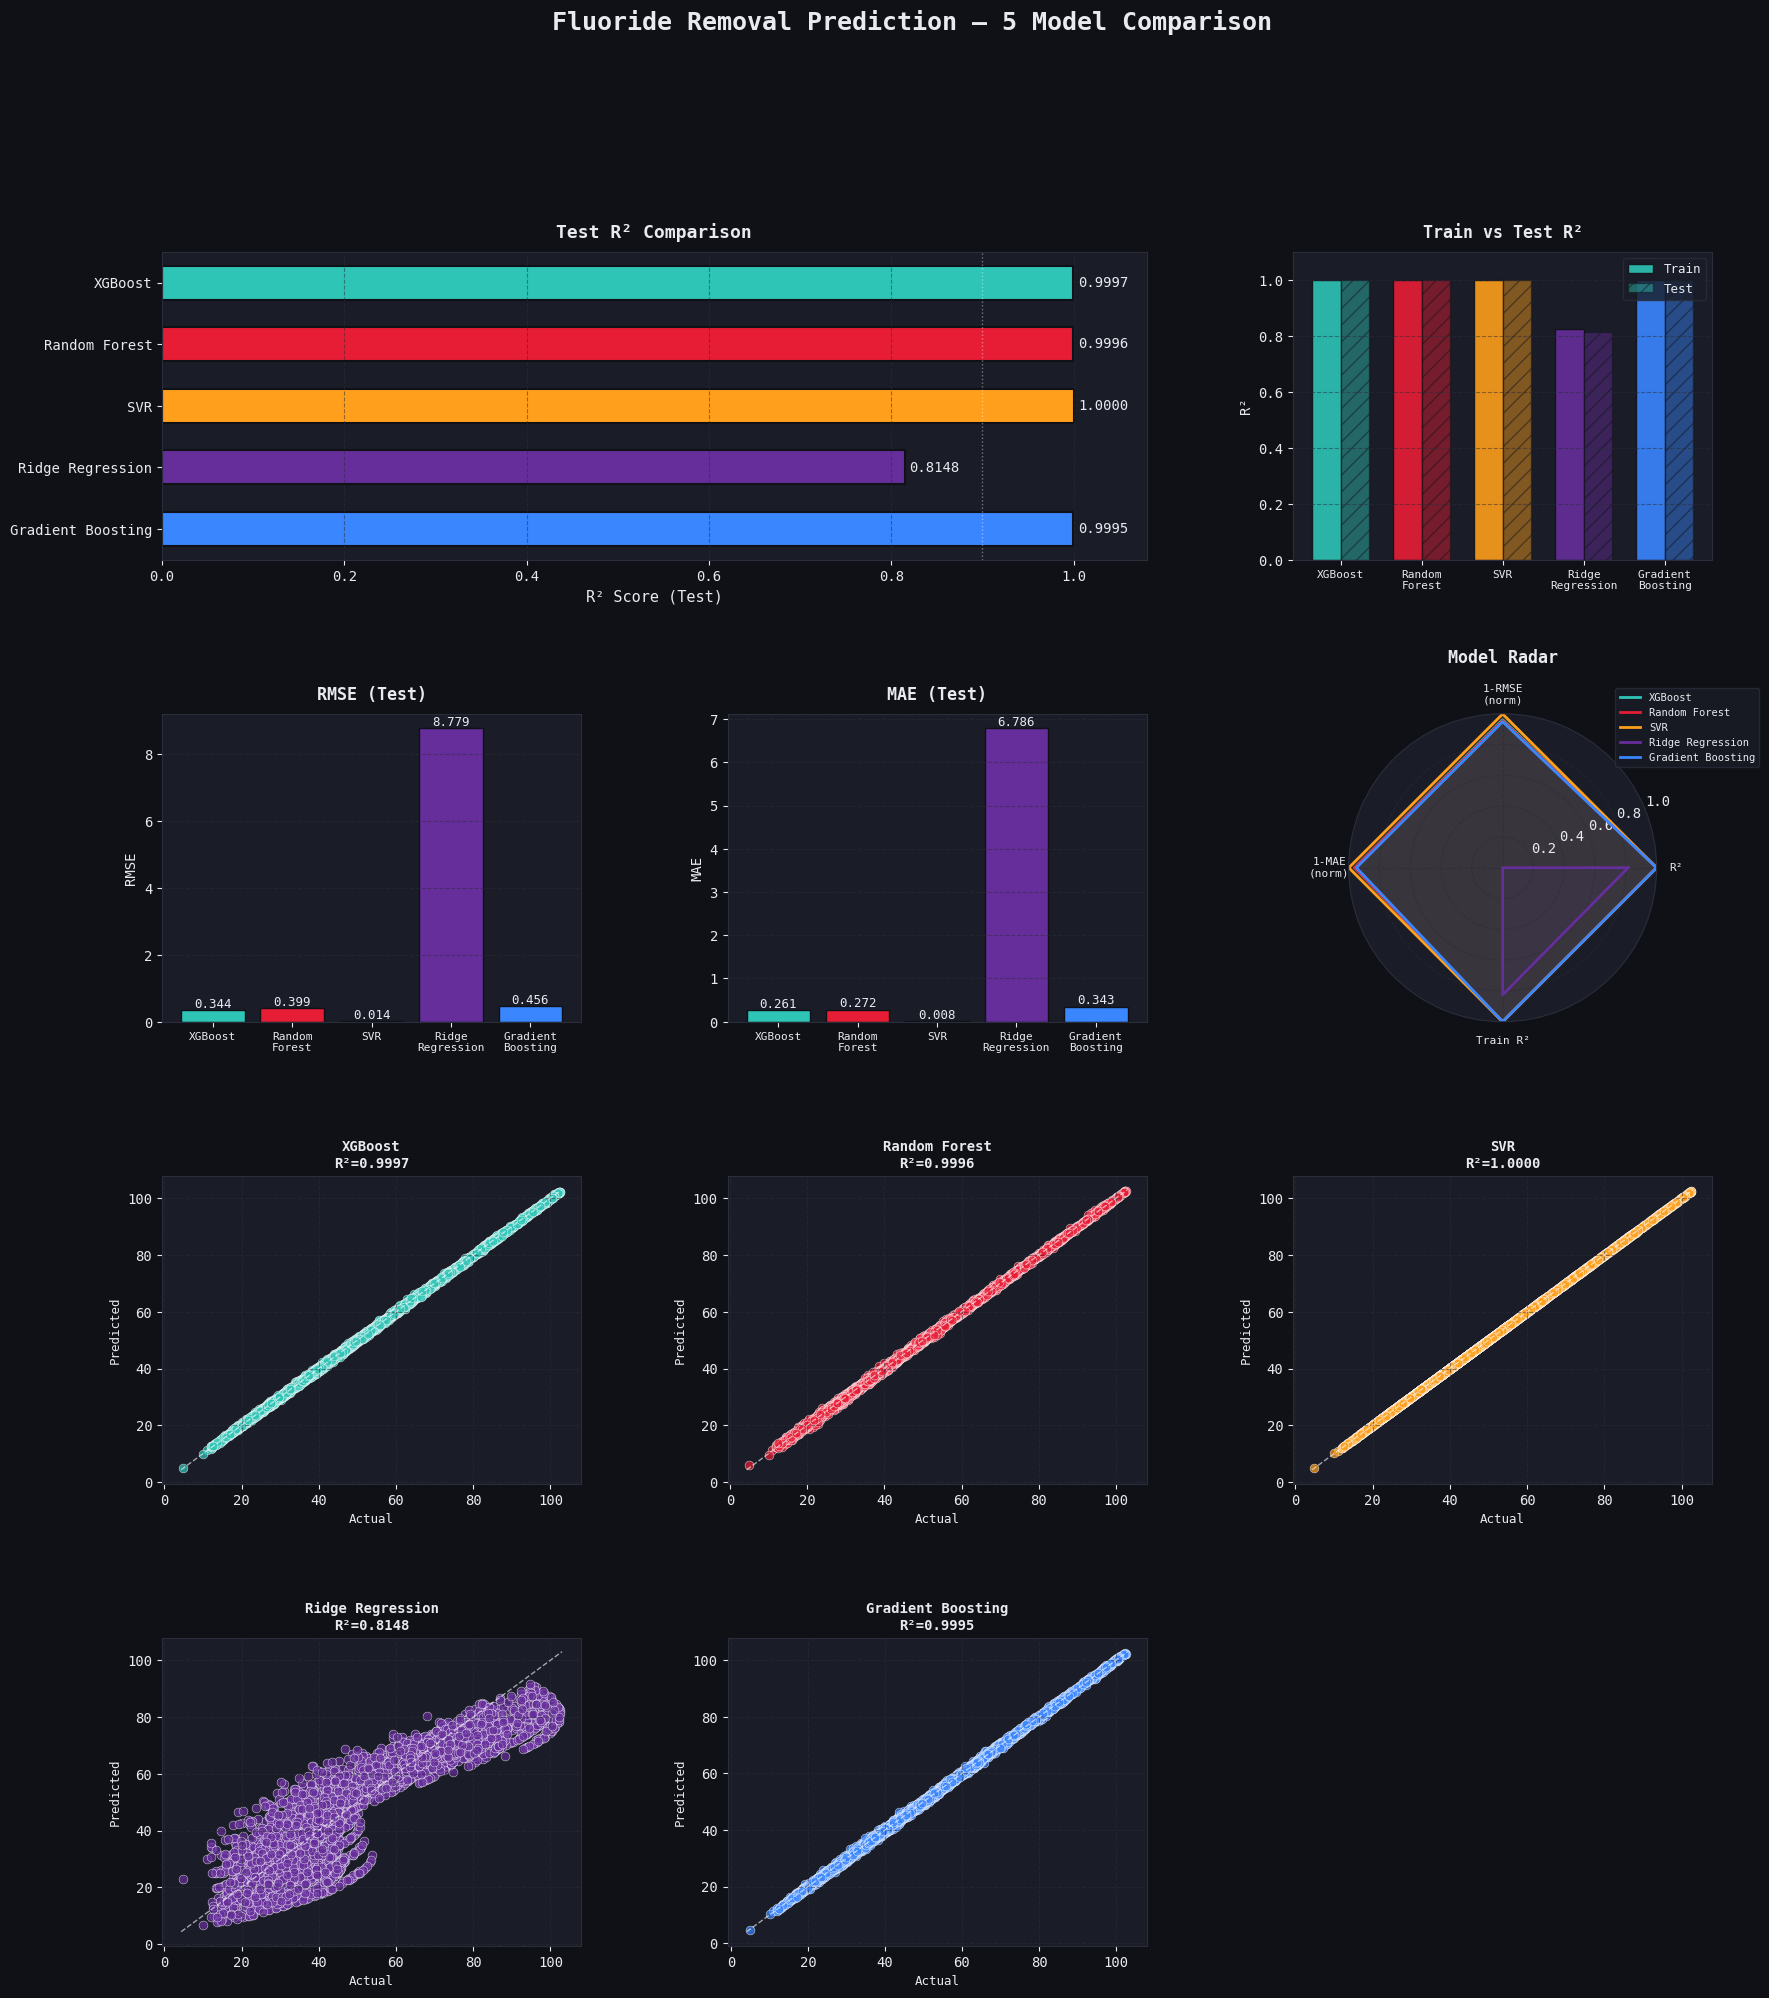

✅ Plot saved → model_comparison.png


In [8]:
# ─────────────────────────────────────────────
# 5. Comparison Plots
# ─────────────────────────────────────────────

model_names = list(results.keys())
test_r2s    = [results[m]["test_r2"]   for m in model_names]
test_rmses  = [results[m]["test_rmse"] for m in model_names]
test_maes   = [results[m]["test_mae"]  for m in model_names]
train_r2s   = [results[m]["train_r2"]  for m in model_names]

COLORS = ["#2EC4B6", "#E71D36", "#FF9F1C", "#662E9B", "#3A86FF"]
BG     = "#0F1117"
PANEL  = "#1A1D27"
TEXT   = "#E8EAF0"
GRID_C = "#2A2D3A"

plt.rcParams.update({
    "font.family":      "monospace",
    "text.color":       TEXT,
    "axes.facecolor":   PANEL,
    "figure.facecolor": BG,
    "axes.edgecolor":   GRID_C,
    "axes.labelcolor":  TEXT,
    "xtick.color":      TEXT,
    "ytick.color":      TEXT,
    "grid.color":       GRID_C,
    "grid.linestyle":   "--",
    "grid.alpha":       0.5
})

fig = plt.figure(figsize=(20, 22), facecolor=BG)
fig.suptitle("Fluoride Removal Prediction — 5 Model Comparison",
             fontsize=18, fontweight="bold", color=TEXT, y=0.99)

gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.5, wspace=0.35)

# ── Plot 1: Test R² Bar Chart ──────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
bars = ax1.barh(model_names, test_r2s, color=COLORS, height=0.55,
                edgecolor=BG, linewidth=1.5)
ax1.set_xlabel("R² Score (Test)", fontsize=11)
ax1.set_title("Test R² Comparison", fontsize=13, fontweight="bold", pad=10)
ax1.set_xlim(0, 1.08)
ax1.axvline(0.9, color="white", linestyle=":", alpha=0.4, linewidth=1)
for bar, val in zip(bars, test_r2s):
    ax1.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
             f"{val:.4f}", va="center", fontsize=10, color=TEXT)
ax1.grid(axis="x")
ax1.invert_yaxis()

# ── Plot 2: Train vs Test R² Grouped Bar ──────────────────────
ax2 = fig.add_subplot(gs[0, 2])
x = np.arange(len(model_names))
w = 0.35
ax2.bar(x - w/2, train_r2s, w, label="Train", color=COLORS, alpha=0.9, edgecolor=BG)
ax2.bar(x + w/2, test_r2s,  w, label="Test",  color=COLORS, alpha=0.45,
        edgecolor=BG, hatch="//")
ax2.set_xticks(x)
ax2.set_xticklabels([m.replace(" ", "\n") for m in model_names], fontsize=8)
ax2.set_ylabel("R²", fontsize=10)
ax2.set_title("Train vs Test R²", fontsize=12, fontweight="bold", pad=10)
ax2.legend(fontsize=9, facecolor=PANEL, edgecolor=GRID_C)
ax2.set_ylim(0, 1.1)
ax2.grid(axis="y")

# ── Plot 3: RMSE Bar ───────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
ax3.bar(model_names, test_rmses, color=COLORS, edgecolor=BG)
ax3.set_title("RMSE (Test)", fontsize=12, fontweight="bold", pad=10)
ax3.set_ylabel("RMSE")
ax3.set_xticks(range(len(model_names)))
ax3.set_xticklabels([m.replace(" ", "\n") for m in model_names], fontsize=8)
ax3.grid(axis="y")
for i, v in enumerate(test_rmses):
    ax3.text(i, v + max(test_rmses) * 0.01, f"{v:.3f}",
             ha="center", fontsize=9, color=TEXT)

# ── Plot 4: MAE Bar ────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ax4.bar(model_names, test_maes, color=COLORS, edgecolor=BG)
ax4.set_title("MAE (Test)", fontsize=12, fontweight="bold", pad=10)
ax4.set_ylabel("MAE")
ax4.set_xticks(range(len(model_names)))
ax4.set_xticklabels([m.replace(" ", "\n") for m in model_names], fontsize=8)
ax4.grid(axis="y")
for i, v in enumerate(test_maes):
    ax4.text(i, v + max(test_maes) * 0.01, f"{v:.3f}",
             ha="center", fontsize=9, color=TEXT)

# ── Plot 5: Radar Chart ────────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 2], polar=True)
metrics_radar = ["R²", "1-RMSE\n(norm)", "1-MAE\n(norm)", "Train R²"]
N      = len(metrics_radar)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

rmse_norm = 1 - (np.array(test_rmses) / max(test_rmses))
mae_norm  = 1 - (np.array(test_maes)  / max(test_maes))

for i, name in enumerate(model_names):
    vals = [test_r2s[i], rmse_norm[i], mae_norm[i], train_r2s[i]]
    vals += vals[:1]
    ax5.plot(angles, vals, color=COLORS[i], linewidth=2, label=name)
    ax5.fill(angles, vals, color=COLORS[i], alpha=0.07)

ax5.set_xticks(angles[:-1])
ax5.set_xticklabels(metrics_radar, fontsize=8, color=TEXT)
ax5.set_ylim(0, 1)
ax5.set_facecolor(PANEL)
ax5.grid(color=GRID_C)
ax5.set_title("Model Radar", fontsize=12, fontweight="bold", pad=15)
ax5.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1),
           fontsize=7.5, facecolor=PANEL, edgecolor=GRID_C)

# ── Plots 6–10: Actual vs Predicted per model ─────────────────
scatter_positions = [(2, 0), (2, 1), (2, 2), (3, 0), (3, 1)]
for idx, (row, col) in enumerate(scatter_positions):
    name = model_names[idx]
    ax   = fig.add_subplot(gs[row, col])
    yp   = results[name]["y_pred_test"]
    yt   = y_test.values
    ax.scatter(yt, yp, color=COLORS[idx], alpha=0.7, s=40,
               edgecolors="white", linewidths=0.4)
    mn = min(yt.min(), yp.min()) - 0.5
    mx = max(yt.max(), yp.max()) + 0.5
    ax.plot([mn, mx], [mn, mx], "w--", linewidth=1, alpha=0.6)
    ax.set_xlabel("Actual", fontsize=9)
    ax.set_ylabel("Predicted", fontsize=9)
    ax.set_title(f"{name}\nR²={results[name]['test_r2']:.4f}",
                 fontsize=10, fontweight="bold")
    ax.grid(True)

plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight",
            facecolor=BG, edgecolor="none")
plt.show()
print("✅ Plot saved → model_comparison.png")

In [9]:
# ─────────────────────────────────────────────
# 6. Save All Test Predictions
# ─────────────────────────────────────────────

pred_df = pd.DataFrame({"Actual": y_test.values})
for name in model_names:
    col = name.replace(" ", "_")
    pred_df[f"Pred_{col}"] = results[name]["y_pred_test"]

pred_df.to_csv("all_model_predictions.csv", index=False)
print("✅ Predictions saved → all_model_predictions.csv")

✅ Predictions saved → all_model_predictions.csv
